# New York City Taxi Fare Prediction

## Overview

This project uses an artificial neural network (ANN) to predict the fare amount of a New York City taxi trip. The model learns from trip details such as pickup and dropoff locations, pickup time, and passenger count.

The goal is to use these features to estimate the trip fare for records where the fare is unknown.

## Dataset

The dataset comes from the [New York City Taxi Fare Prediction competition on Kaggle](https://www.kaggle.com/competitions/new-york-city-taxi-fare-prediction).

It contains:

- `data.csv` — trip information and the known fare, used to train and evaluate the model.

### Data fields

| Field | Description |
|---|---|
| `key` | Unique identifier for each trip. Used to match predictions to test rows. |
| `pickup_datetime` | Date and time the trip started. |
| `pickup_longitude` | Longitude of the pickup location. |
| `pickup_latitude` | Latitude of the pickup location. |
| `dropoff_longitude` | Longitude of the dropoff location. |
| `dropoff_latitude` | Latitude of the dropoff location. |
| `passenger_count` | Number of passengers. |
| `fare_amount` | Trip fare in dollars; this is the value the model predicts. |

## Project Workflow

1. Load and inspect the training data.
2. Clean the data and handle missing or invalid values.
3. Prepare useful model inputs from the trip details.
4. Split the training data into training and validation sets.
5. Train an ANN to predict `fare_amount`.
6. Evaluate predictions using a regression metric such as root mean squared error (RMSE).
7. Generate fare predictions for the test data and save them in the required submission format.

## Model

The project uses a feed-forward artificial neural network for regression. It takes processed trip features as input and produces an estimated fare amount.

The model’s performance depends on data preparation, feature selection, and training settings. No performance score is stated here; add your measured validation or competition result after running the model.

## Tools

- Python
- pandas
- NumPy
- scikit-learn
- PyTorch


## Acknowledgements

Dataset provided through Kaggle’s [New York City Taxi Fare Prediction](https://www.kaggle.com/competitions/new-york-city-taxi-fare-prediction) competition, hosted in partnership with Google Cloud and Coursera.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

In [2]:
df = pd.read_csv('NYCTaxiFares.csv')
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   pickup_datetime    120000 non-null  object 
 1   fare_amount        120000 non-null  float64
 2   fare_class         120000 non-null  int64  
 3   pickup_longitude   120000 non-null  float64
 4   pickup_latitude    120000 non-null  float64
 5   dropoff_longitude  120000 non-null  float64
 6   dropoff_latitude   120000 non-null  float64
 7   passenger_count    120000 non-null  int64  
dtypes: float64(5), int64(2), object(1)
memory usage: 7.3+ MB


In [4]:
df.isnull().any().sum()

0

In [5]:
# We work on a dataset relateded to New York city time which is 4 hours difference from our datetime 
df['EDTdate'] = pd.to_datetime(df['pickup_datetime']) - pd.Timedelta(hours=4)

In [6]:
# We can build a distance column to help our model predict better using haversine computation
def haversine_distance(df, lat1, long1, lat2, long2):
    """
    Calculates the haversine distance between 2 sets of GPS coordinates in df
    """
    r = 6371  # average radius of Earth in kilometers
       
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])
    
    delta_phi = np.radians(df[lat2]-df[lat1])
    delta_lambda = np.radians(df[long2]-df[long1])
     
    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    d = (r * c) # in kilometers

    return d

In [7]:
df.columns

Index(['pickup_datetime', 'fare_amount', 'fare_class', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count', 'EDTdate'],
      dtype='object')

In [8]:
df['KM'] = haversine_distance(df,'pickup_latitude','pickup_longitude','dropoff_latitude','dropoff_longitude' )

In [9]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,EDTdate,KM
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2010-04-19 04:17:56+00:00,2.126312
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,2010-04-17 11:43:53+00:00,1.392307
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,2010-04-17 07:23:26+00:00,3.326763
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,2010-04-11 17:25:03+00:00,1.864129
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,2010-04-16 22:19:01+00:00,7.231321


In [10]:
df.describe()['fare_amount'].T

count    120000.000000
mean         10.040326
std           7.500134
min           2.500000
25%           5.700000
50%           7.700000
75%          11.300000
max          49.900000
Name: fare_amount, dtype: float64

```
We might find out the mean of fare_amount as a boarder

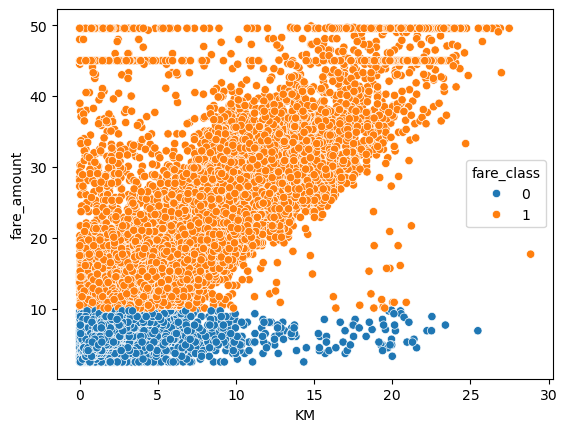

In [11]:
sns.scatterplot(df, x='KM', y='fare_amount',hue='fare_class');

```
The fare_amount under 10$ is refered to class 0 and above it related to class 1.
we can keep the fare_amount column for a future classification prediction.

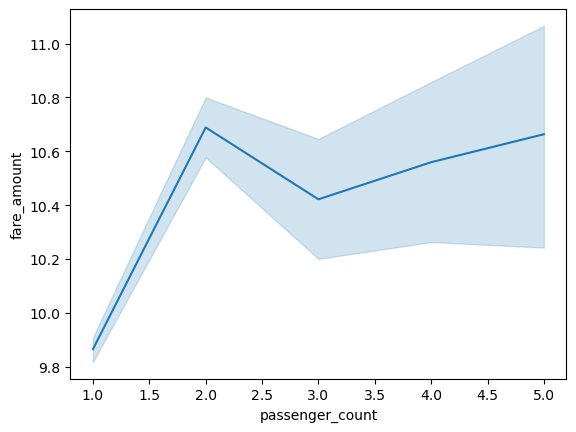

In [12]:
sns.lineplot(df, x='passenger_count', y='fare_amount');

In [13]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,EDTdate,KM
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2010-04-19 04:17:56+00:00,2.126312
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,2010-04-17 11:43:53+00:00,1.392307
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,2010-04-17 07:23:26+00:00,3.326763
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,2010-04-11 17:25:03+00:00,1.864129
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,2010-04-16 22:19:01+00:00,7.231321


In [14]:
numeric = df.select_dtypes(exclude='object')
numeric.drop('EDTdate', axis=1, inplace=True)

In [15]:
df.corr(numeric_only=True)['fare_amount'][1:].sort_values(ascending=False)

KM                   0.896157
fare_class           0.690037
dropoff_longitude    0.413033
pickup_longitude     0.396492
passenger_count      0.034072
dropoff_latitude    -0.164657
pickup_latitude     -0.179085
Name: fare_amount, dtype: float64

In [16]:
# To feed our Neural Network model, we need to create an embeding size of categorical data 
# and convert all data to tensor, so the model can train better in each epoch and find a better weights for each observation.

In [17]:
# Let's first create a columns of time and stack them together

df['hour'] = df['EDTdate'].dt.hour
df['AMorPM'] = np.where(df['hour']<12,'am','pm')
df['weekday'] = df['EDTdate'].dt.strftime('%a')
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,EDTdate,KM,hour,AMorPM,weekday
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2010-04-19 04:17:56+00:00,2.126312,4,am,Mon
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,2010-04-17 11:43:53+00:00,1.392307,11,am,Sat
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,2010-04-17 07:23:26+00:00,3.326763,7,am,Sat
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,2010-04-11 17:25:03+00:00,1.864129,17,pm,Sun
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,2010-04-16 22:19:01+00:00,7.231321,22,pm,Fri


In [18]:
df.columns

Index(['pickup_datetime', 'fare_amount', 'fare_class', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count', 'EDTdate', 'KM', 'hour', 'AMorPM', 'weekday'],
      dtype='object')

In [19]:
# we split all column in three columns

cat_col = ['hour', 'AMorPM', 'weekday']
cont_col = ['pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count', 'KM']    # for now we remove the fare_class from our data
y_col = ['fare_amount']

In [20]:
# Change the dtype of cat_col to category

for col in cat_col:
    df[col] = df[col].astype('category')

In [21]:
df.info()
print('='*40)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   pickup_datetime    120000 non-null  object             
 1   fare_amount        120000 non-null  float64            
 2   fare_class         120000 non-null  int64              
 3   pickup_longitude   120000 non-null  float64            
 4   pickup_latitude    120000 non-null  float64            
 5   dropoff_longitude  120000 non-null  float64            
 6   dropoff_latitude   120000 non-null  float64            
 7   passenger_count    120000 non-null  int64              
 8   EDTdate            120000 non-null  datetime64[ns, UTC]
 9   KM                 120000 non-null  float64            
 10  hour               120000 non-null  category           
 11  AMorPM             120000 non-null  category           
 12  weekday            120000 non-

````
this step might be alittle complex, so we should pay attention what is going on in this step cause
we might need to know how the data is feeded to the model.

In [22]:
hr = df['hour'].cat.codes.values
ampm = df['AMorPM'].cat.codes.values
wday = df['weekday'].cat.codes.values

cats = np.stack([hr,ampm,wday],axis=1) # we concatnate them in y axis or based on column

In [23]:
cats

array([[ 4,  0,  1],
       [11,  0,  2],
       [ 7,  0,  2],
       ...,
       [14,  1,  3],
       [ 4,  0,  5],
       [12,  1,  2]], dtype=int8)

In [24]:
cats = torch.tensor(cats, dtype=torch.int64)
cats

tensor([[ 4,  0,  1],
        [11,  0,  2],
        [ 7,  0,  2],
        ...,
        [14,  1,  3],
        [ 4,  0,  5],
        [12,  1,  2]])

In [25]:
conts = np.stack([df[col].values for col in cont_col],axis=1)
conts

array([[-73.992365  ,  40.730521  , -73.975499  ,  40.744746  ,
          1.        ,   2.12631159],
       [-73.990078  ,  40.740558  , -73.974232  ,  40.744114  ,
          1.        ,   1.39230687],
       [-73.994149  ,  40.751118  , -73.960064  ,  40.766235  ,
          2.        ,   3.32676344],
       ...,
       [-73.988574  ,  40.749772  , -74.011541  ,  40.707799  ,
          3.        ,   5.05252282],
       [-74.004449  ,  40.724529  , -73.992697  ,  40.730765  ,
          1.        ,   1.20892296],
       [-73.955415  ,  40.77192   , -73.967623  ,  40.763015  ,
          3.        ,   1.42739869]])

In [26]:
conts = torch.tensor(conts, dtype=torch.float)
conts

tensor([[-73.9924,  40.7305, -73.9755,  40.7447,   1.0000,   2.1263],
        [-73.9901,  40.7406, -73.9742,  40.7441,   1.0000,   1.3923],
        [-73.9941,  40.7511, -73.9601,  40.7662,   2.0000,   3.3268],
        ...,
        [-73.9886,  40.7498, -74.0115,  40.7078,   3.0000,   5.0525],
        [-74.0044,  40.7245, -73.9927,  40.7308,   1.0000,   1.2089],
        [-73.9554,  40.7719, -73.9676,  40.7630,   3.0000,   1.4274]])

In [27]:
y = torch.tensor(df[y_col].values, dtype=torch.float)
y

tensor([[ 6.5000],
        [ 6.9000],
        [10.1000],
        ...,
        [12.5000],
        [ 4.9000],
        [ 5.3000]])

In [33]:
cols = [cats,conts,y]

for item in cols:
    print(item.shape)

print('-'*100)

torch.Size([120000, 3])
torch.Size([120000, 6])
torch.Size([120000, 1])
----------------------------------------------------------------------------------------------------


.

.

````
Now it is time to create our embedding size

In [29]:
cats_size = [len(df[col].cat.categories) for col in cat_col]
cats_size

[24, 2, 7]

In [30]:
emb_size = [(size, min(50, (size+1)//2)) for size in cats_size]

In [31]:
emb_size

[(24, 12), (2, 1), (7, 4)]

````
this tuples are very important cause we feed them to our model

````
Finally we have the following inputs:
_emb_size
_n_cont = 6  numerical dimensions
out_size = 1 as a regression, a single value as an output


Categorical features:
Hour      → 24 possible values → 12 embedding values
AMorPM    →  2 possible values →  1 embedding value
Weekday   →  7 possible values →  4 embedding values

Continuous features:
6 values: coordinates, passenger count, distance

Output:
1 value: predicted fare

### We create the model

In [44]:
# the class does not train the model, it only builds the model and moves data through it

class TaxiModel(nn.Module):
    def __init__(self, emb_size, n_cont, out_size, layers,p):
        super().__init__()
        self.embeds = nn.ModuleList([nn.Embedding(ni,nf) for ni,nf in emb_size])  # a short way of creating embeding tabels
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)

        layerlist = []
        n_emb = sum((nf for ni, nf in emb_size)) # the num of emb features for num of categories
        n_in = n_emb + n_cont

        for i in layers:
            layerlist.append(nn.Linear(n_in,i)) # 23 --> 200
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i # the next layer must accept current values

        layerlist.append(nn.Linear(layers[-1], out_size)) # layers[-1] means the last hidden layer
        self.layers = nn.Sequential(*layerlist) # it take all layer form layerlist and run in order


    def forward(self,x_cat, x_cont):
        embeddings = []  # it is created each time(temporary) the forward() runs
        for i, e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:,i]))
        x = torch.cat(embeddings,1) # joining all embedding outputs
        x = self.emb_drop(x)

        conts = self.bn_cont(x_cont)
        x = torch.cat([x, conts],1) # combine all categories and continuous values
        x = self.layers(x)
        return x

.

.

In [66]:
torch.manual_seed(101)
model = TaxiModel(emb_size, conts.shape[1],1, [200,200,100], p=0.3)

In [67]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
batch_size = 60000
test_size = int(batch_size * .2)

cat_train = cats[:batch_size-test_size]
cat_test = cats[batch_size-test_size:batch_size]
con_train = conts[:batch_size-test_size]
con_test = conts[batch_size-test_size:batch_size]
y_train = y[:batch_size-test_size]
y_test = y[batch_size-test_size:batch_size]

In [68]:
import time
start_time = time.time()

epochs = 300
losses = []

for i in range(epochs):
    i+=1
    y_pred = model(cat_train, con_train)
    loss = torch.sqrt(criterion(y_pred, y_train)) # RMSE
    losses.append(loss.detach().numpy())
    
    # a neat trick to save screen space:
    if i%25 == 1:
        print(f'epoch: {i}  loss: {loss}')

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

duration = time.time() - start_time
print(f'Training took {duration/60} minutes')

epoch: 1  loss: 12.480377197265625
epoch: 26  loss: 10.541275978088379
epoch: 51  loss: 10.087356567382812
epoch: 76  loss: 9.69282341003418
epoch: 101  loss: 9.15958023071289
epoch: 126  loss: 8.39272689819336
epoch: 151  loss: 7.350987911224365
epoch: 176  loss: 6.118962287902832
epoch: 201  loss: 4.86089563369751
epoch: 226  loss: 3.903273820877075
epoch: 251  loss: 3.5958611965179443
epoch: 276  loss: 3.5021400451660156
Training took 1.6124288280804953 minutes


In [69]:
# TO EVALUATE THE ENTIRE TEST SET
with torch.no_grad():
    y_val = model(cat_test, con_test)
    loss = torch.sqrt(criterion(y_val, y_test))
print(f'RMSE: {loss}')

RMSE: 3.383028984069824


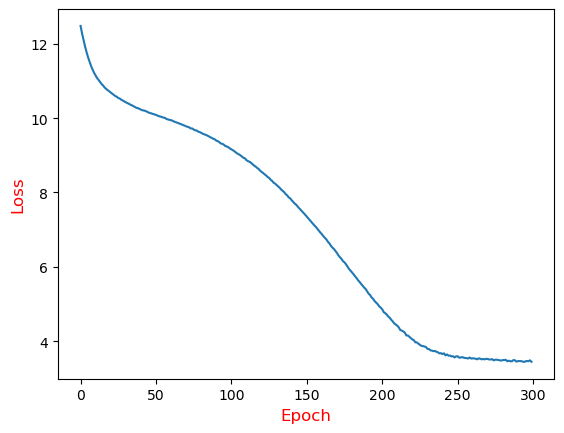

In [71]:
plt.plot(range(epochs), losses)
plt.xlabel('Epoch',c='r',fontsize=12)
plt.ylabel('Loss', c='r', fontsize=12);

In [72]:
for i in range(20):
    diff = np.abs(y_val[i].item()-y_test[i].item())
    print(f'{i}.) PREDICTED: {y_val[i].item():8.2f} TRUE {y_test[i].item():8.2f} DIFF: {diff:8.2f}')

0.) PREDICTED:     4.55 TRUE     2.90 DIFF:     1.65
1.) PREDICTED:    22.48 TRUE     5.70 DIFF:    16.78
2.) PREDICTED:     5.93 TRUE     7.70 DIFF:     1.77
3.) PREDICTED:    13.59 TRUE    12.50 DIFF:     1.09
4.) PREDICTED:     5.63 TRUE     4.10 DIFF:     1.53
5.) PREDICTED:     4.68 TRUE     5.30 DIFF:     0.62
6.) PREDICTED:     2.35 TRUE     3.70 DIFF:     1.35
7.) PREDICTED:    16.02 TRUE    14.50 DIFF:     1.52
8.) PREDICTED:     4.04 TRUE     5.70 DIFF:     1.66
9.) PREDICTED:    12.25 TRUE    10.10 DIFF:     2.15
10.) PREDICTED:     6.25 TRUE     4.50 DIFF:     1.75
11.) PREDICTED:     8.49 TRUE     6.10 DIFF:     2.39
12.) PREDICTED:     6.45 TRUE     6.90 DIFF:     0.45
13.) PREDICTED:    11.43 TRUE    14.10 DIFF:     2.67
14.) PREDICTED:     4.37 TRUE     4.50 DIFF:     0.13
15.) PREDICTED:    32.33 TRUE    34.10 DIFF:     1.77
16.) PREDICTED:     5.38 TRUE    12.50 DIFF:     7.12
17.) PREDICTED:     3.54 TRUE     4.10 DIFF:     0.56
18.) PREDICTED:     9.19 TRUE     8.50

In [73]:
df['fare_amount'].mean()

10.040326083333337

```
Our Model has shown a good performance

In [75]:
torch.save(model.state_dict(), 'taximodel.pt')